<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Bureau of Labor Statistics](https://github.com/Query-farm/vgi-bls)

Retrieve labor, employment, price and productivity series with period codes, footnotes, calculations and survey metadata.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-bls/blob/main/notebooks/02_popular_does_not_mean_comparable.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-bls/blob/main/notebooks/README.md)


## 02 · Popular does not mean comparable—or equally recent

Which popular-series candidates can join a **U.S., unadjusted consumer-price index**
comparison, and do their latest observations describe the same month? Discover the
survey context, retrieve catalog fields, then separate measurement compatibility from
a policy on period lag. Popularity supplies candidates, not units or an exhaustive catalog.

**This entire story uses synthetic identifiers, metadata, periods and values** served
by an explicit loopback fixture through the real released BLS worker. It is not a
recording of BLS, not an inflation estimate, and not evidence about live catalog
availability. A fake temporary key exercises the registered `series()` path locally.
Notebook 01 separately uses live, unregistered official CPI observations.

### Change the permitted period lag

`MAX_LAG_MONTHS = 0` requires the latest month shared by the most recent comparable
candidate. Set it to **1** for the experiment, admitting a comparable series one
month behind. This changes only a selection policy; all five candidates, their
metadata and returned observations remain fixed. A lagged month is not relabeled
as current, and neither policy claims a real-time publication timestamp.

In [1]:
MAX_LAG_MONTHS = 0  # Experiment: 1.

### Run this notebook

Read the saved results on GitHub or use **Open in Colab** and Run All. The shared
base preserves compatible preloaded plotting/data libraries; local publication uses
its separate `[runner]` extra. Initial packages, verified companions, VGI and the
released worker need internet. uv provisions the worker's Python 3.13+ environment.
No checkout or local worker build is needed. A fresh preloaded Python 3.12 notebook-only
run verifies setup; actual hosted Colab has not been tested.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.33":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.33"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.33":
    raise RuntimeError("Install shared tools 0.3.33, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks.bootstrap import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("bls")
from bls_example import BLSSource

%matplotlib inline
theme()
session = connect(globals())
con = session.connection
Path("artifacts").mkdir(exist_ok=True)

if type(MAX_LAG_MONTHS) is not int or MAX_LAG_MONTHS not in {0, 1}:
    raise ValueError("MAX_LAG_MONTHS must be 0 or 1")
source = BLSSource("synthetic")
PROVENANCE = "Source: entirely synthetic BLS-shaped loopback fixture · not official estimates · released v0.1.0"

### Make the local credential boundary explicit

Shared setup creates an empty temporary SQL-secret store and disables persistent
secrets before ATTACH. The fake key below is accepted **only by this local fixture**;
it is not a BLS registration key. The helper clears inherited BLS settings and starts
an ephemeral read-only HTTP service on 127.0.0.1. It never forwards requests upstream.
Each remote call is materialized once, before local capture/display, to avoid repeated
API requests. `max_rows` caps output; it does not change the upstream request.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'bls' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-bls@v0.1.0 vgi-bls-worker');
CREATE TEMPORARY SECRET bls_notebook_fixture (
 TYPE bls_api, api_key 'NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN');

,Success


In [5]:
secrets = con.execute("SELECT name, persistent FROM duckdb_secrets()").fetchall()
assert secrets == [("bls_notebook_fixture", False)]

In [6]:
%%sql
CREATE TABLE surveys AS SELECT * FROM bls.main.surveys();
CREATE TABLE popular AS SELECT * FROM bls.main.popular_series();
SELECT * FROM surveys ORDER BY survey_abbreviation;
SELECT series_id FROM popular ORDER BY series_id;

,series_id
0,CUDEMOLAG
1,CUDEMOLEVEL
2,CUDEMOREGION
3,CUDEMOSA
4,LNDEMORATE


### Retrieve measurement fields before selecting a comparison

The popular list contains IDs only, with no rank scores or measurement dimensions.
`series()` requires registration in the real API and returns catalog metadata from
a bounded batch response that also carries observations upstream. Here five fixed
synthetic IDs and one year are explicit. Matching survey abbreviations joins
published-style capability fields; an omitted flag stays NULL rather than false.

For this example's stated comparison, require **CU**, **United States**,
**Not Seasonally Adjusted**, and **Index, synthetic base=100**. These are explicit
teaching contracts, not universal rules for every BLS comparison. Exact catalog
strings are inspected; no geography or units are inferred from the ID.

In [7]:
%%sql
CREATE TABLE catalog AS SELECT * FROM bls.main.series(
 ['CUDEMOLEVEL','CUDEMOLAG','CUDEMOSA','CUDEMOREGION','LNDEMORATE'],2024,2024);
CREATE TABLE candidates AS
SELECT p.series_id,c.series_title,c.survey_abbreviation,c.seasonality,c.measure_data_type,c.area,
 s.survey_name,s.has_annual_averages,
 c.survey_abbreviation='CU' AS same_survey,
 c.area='United States' AS same_area,
 c.seasonality='Not Seasonally Adjusted' AS same_adjustment,
 c.measure_data_type='Index, synthetic base=100' AS same_units
FROM popular p JOIN catalog c USING(series_id)
LEFT JOIN surveys s USING(survey_abbreviation);
SELECT series_id,series_title,survey_name,seasonality,measure_data_type,area,has_annual_averages
FROM candidates ORDER BY series_id;

,series_id,series_title,survey_name,seasonality,measure_data_type,area,has_annual_averages
0,CUDEMOLAG,"Illustrative core index, delayed period",Synthetic consumer prices,Not Seasonally Adjusted,"Index, synthetic base=100",United States,True
1,CUDEMOLEVEL,Illustrative all-items index,Synthetic consumer prices,Not Seasonally Adjusted,"Index, synthetic base=100",United States,True
2,CUDEMOREGION,Illustrative regional price index,Synthetic consumer prices,Not Seasonally Adjusted,"Index, synthetic base=100",Region A,True
3,CUDEMOSA,Illustrative seasonally adjusted index,Synthetic consumer prices,Seasonally Adjusted,"Index, synthetic base=100",United States,True
4,LNDEMORATE,Illustrative unemployment rate,Synthetic labor force,Seasonally Adjusted,Percent,United States,<NA>


In [8]:
%%sql criteria <<
SELECT *,same_survey AND same_area AND same_adjustment AND same_units AS comparable
FROM candidates ORDER BY series_id;

In [9]:
compatible = int(criteria.comparable.sum())
unknown_capability = int(criteria.has_annual_averages.isna().sum())
prose(
    f"**{len(criteria)} popular candidates** become **{compatible} measurement-compatible candidates**. "
    "The adjusted index, regional index and labor-force rate fail different requirements; "
    "a title or a shared prefix alone would not expose all those distinctions. "
    f"Annual-average support is unknown for **{unknown_capability} candidate**, not false. "
    "That capability is shown for context and is not a criterion in this monthly comparison."
)

**5 popular candidates** become **2 measurement-compatible candidates**. The adjusted index, regional index and labor-force rate fail different requirements; a title or a shared prefix alone would not expose all those distinctions. Annual-average support is unknown for **1 candidate**, not false. That capability is shown for context and is not a criterion in this monthly comparison.

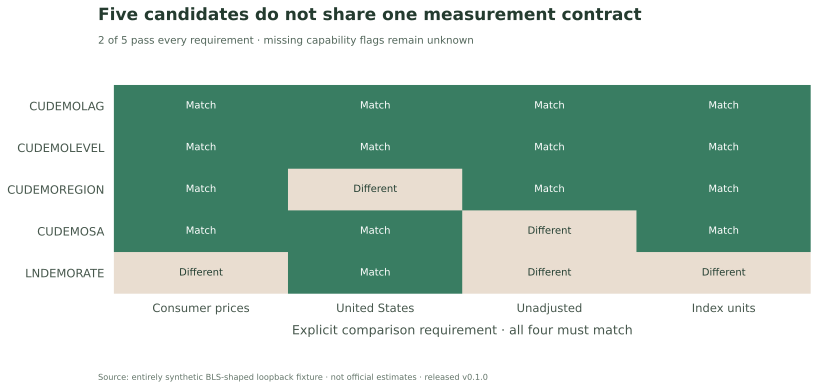

In [10]:
from matplotlib.colors import ListedColormap

columns = ["same_survey", "same_area", "same_adjustment", "same_units"]
matrix = criteria[columns].to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(11, 5.7))
ax.imshow(matrix, cmap=ListedColormap(["#E9DDD0", "#397D62"]), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4), ["Consumer prices", "United States", "Unadjusted", "Index units"])
ax.set_yticks(range(len(criteria)), criteria.series_id)
ax.set_xlabel("Explicit comparison requirement · all four must match")
for row in range(len(criteria)):
    for col in range(4):
        ax.text(
            col,
            row,
            "Match" if matrix[row, col] else "Different",
            ha="center",
            va="center",
            color="white" if matrix[row, col] else "#243F32",
            fontsize=10,
        )
ax.grid(False)
finish(
    fig,
    "Five candidates do not share one measurement contract",
    f"{compatible} of {len(criteria)} pass every requirement · missing capability flags remain unknown",
    PROVENANCE,
    name=f"measurement-contract-{MAX_LAG_MONTHS}",
)

### Latest is per series, not a synchronized publication

Retrieve each candidate's latest observation once. Preserve its native year/period,
original value text and footnotes. Only M01–M12 become monthly dates; an annual-average
M13 or other frequency must not be invented into a month. `latest=true` is a source
flag, not a publication timestamp or proof that two series refer to the same period.

The comparison anchor is the maximum returned monthly period **among comparable
candidates**. The policy counts calendar months behind that anchor. It cannot detect
an unobserved later release, measure ingestion delay, or make stale values current.

In [11]:
%%sql
CREATE TABLE latest_rows AS
SELECT * FROM bls.main.latest('CUDEMOLEVEL') UNION ALL
SELECT * FROM bls.main.latest('CUDEMOLAG') UNION ALL
SELECT * FROM bls.main.latest('CUDEMOSA') UNION ALL
SELECT * FROM bls.main.latest('CUDEMOREGION') UNION ALL
SELECT * FROM bls.main.latest('LNDEMORATE');
CREATE TABLE aligned AS
WITH periods AS (
 SELECT c.*,l.year,l.period,l.value_text,l.latest,l.footnotes_json,
 CASE WHEN regexp_full_match(l.period,'M(0[1-9]|1[0-2])')
 THEN make_date(l.year::INTEGER,substr(l.period,2)::INTEGER,1) END AS observation_month,
 same_survey AND same_area AND same_adjustment AND same_units AS comparable
 FROM candidates c JOIN latest_rows l USING(series_id)
), anchored AS (
 SELECT *,max(observation_month) FILTER(WHERE comparable) OVER() AS anchor_month FROM periods
)
SELECT *,date_diff('month',observation_month,anchor_month) AS lag_months,
 coalesce(comparable AND date_diff('month',observation_month,anchor_month) BETWEEN 0 AND {{MAX_LAG_MONTHS}},false)
 AS selected FROM anchored;
SELECT series_id,period,value_text,latest,observation_month,anchor_month,lag_months,comparable,selected
FROM aligned ORDER BY series_id;

,series_id,period,value_text,latest,observation_month,anchor_month,lag_months,comparable,selected
0,CUDEMOLAG,M11,108.0,True,2024-11-01,2024-12-01,1,True,False
1,CUDEMOLEVEL,M12,110.0,True,2024-12-01,2024-12-01,0,True,True
2,CUDEMOREGION,M12,115.0,True,2024-12-01,2024-12-01,0,False,False
3,CUDEMOSA,M12,109.0,True,2024-12-01,2024-12-01,0,False,False
4,LNDEMORATE,M12,4.5,True,2024-12-01,2024-12-01,0,False,False


In [12]:
%%sql aligned <<
SELECT * FROM aligned ORDER BY series_id;

In [13]:
selected = aligned.loc[aligned.selected, "series_id"].tolist()
prose(
    f"The comparable anchor is **{aligned.anchor_month.max():%Y-%m}**. With an allowed lag (months) of "
    f"**{MAX_LAG_MONTHS}**, **{len(selected)} of {compatible} comparable candidates** are selected: "
    + ", ".join(f"`{s}`" for s in selected)
    + ". "
    "`CUDEMOLAG` remains a November observation even when allowed alongside December. "
    "The synthetic 110 and 108 index readings are not compared as same-month changes; "
    "the 4.5 percent labor-force value is a different unit entirely. All five source latest flags are true, "
    "which alone does not synchronize the periods."
)

The comparable anchor is **2024-12**. With an allowed lag (months) of **0**, **1 of 2 comparable candidates** are selected: `CUDEMOLEVEL`. `CUDEMOLAG` remains a November observation even when allowed alongside December. The synthetic 110 and 108 index readings are not compared as same-month changes; the 4.5 percent labor-force value is a different unit entirely. All five source latest flags are true, which alone does not synchronize the periods.

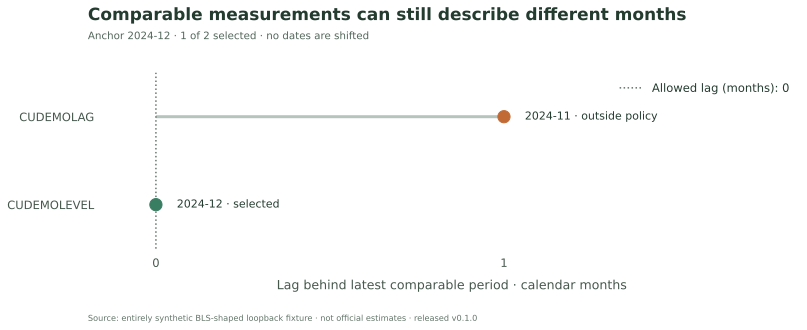

In [14]:
chosen = aligned[aligned.comparable].sort_values("lag_months")
x = np.arange(len(chosen))
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.hlines(x, 0, chosen.lag_months, color="#B6C4BE", linewidth=3)
ax.scatter(chosen.lag_months, x, s=150, c=["#397D62" if v else "#C26A35" for v in chosen.selected], zorder=3)
for i, row in enumerate(chosen.itertuples()):
    ax.text(
        row.lag_months + 0.06,
        i,
        f"{row.observation_month:%Y-%m} · {'selected' if row.selected else 'outside policy'}",
        va="center",
    )
ax.axvline(MAX_LAG_MONTHS, color="#66756C", linestyle=":", label=f"Allowed lag (months): {MAX_LAG_MONTHS}")
ax.set_yticks(x, chosen.series_id)
ax.set_xticks([0, 1])
ax.set_xlim(-0.15, 1.85)
ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("Lag behind latest comparable period · calendar months")
ax.legend(loc="upper right")
finish(
    fig,
    "Comparable measurements can still describe different months",
    f"Anchor {chosen.anchor_month.max():%Y-%m} · {len(selected)} of {compatible} selected · no dates are shifted",
    PROVENANCE,
    name=f"period-lag-{MAX_LAG_MONTHS}",
)

### Check the selection and the request boundary

These checks cover row multiplicity, complete metadata joins, explicit capability
NULLs, native monthly periods, the source latest flag and exact selection logic.
The fixture audit expects **eight requests**: survey discovery, popular discovery,
one bounded catalog POST and five latest GETs. Local SQL displays do not add calls.
The fake secret is temporary and is dropped before the isolated session is closed.

In [15]:
%%sql checks <<
SELECT 'five unique popular IDs' AS check_name,count(*)=5 AND count(DISTINCT series_id)=5 AS passed FROM popular
UNION ALL SELECT 'metadata covers all candidates',count(*)=5 AND count(DISTINCT series_id)=5 FROM candidates
UNION ALL SELECT 'three survey definitions',count(*)=3 FROM surveys
UNION ALL SELECT 'unknown annual support retained',count(*) FILTER(WHERE has_annual_averages IS NULL)=1 FROM candidates
UNION ALL SELECT 'two comparable measurements',count(*) FILTER(WHERE comparable)=2 FROM aligned
UNION ALL SELECT 'five unique latest rows',count(*)=5 AND count(DISTINCT series_id)=5 FROM latest_rows
UNION ALL SELECT 'all fixture periods monthly',count(*) FILTER(WHERE observation_month IS NULL)=0 FROM aligned
UNION ALL SELECT 'source latest flags retained',bool_and(latest) FROM latest_rows
UNION ALL SELECT 'latest differs by one month',max(lag_months)-min(lag_months)=1 FROM aligned WHERE comparable
UNION ALL SELECT 'policy only selects comparable rows',bool_and(NOT selected OR comparable) FROM aligned
UNION ALL SELECT 'expected selection count',count(*) FILTER(WHERE selected)=1+{{MAX_LAG_MONTHS}} FROM aligned
UNION ALL SELECT 'synthetic footnotes retained',count(*) FILTER(WHERE footnotes_json LIKE '%Synthetic teaching fixture%')=5 FROM latest_rows;

In [16]:
display(checks)
assert len(checks) == 12 and checks.passed.all()
assert len(source.audit) == 8
assert sum(x["method"] == "POST" for x in source.audit) == 1
prose(
    "**All 12 SQL checks pass**, with exactly **eight local fixture requests** and one catalog POST. "
    "No live registration key or saved SQL secret was used."
)
Path("artifacts/discovery-audit.json").write_text(
    json.dumps(
        {
            "max_lag_months": MAX_LAG_MONTHS,
            "criteria": criteria.to_dict("records"),
            "aligned": aligned.to_dict("records"),
            "selected": selected,
            "checks": checks.to_dict("records"),
            "request_audit": source.audit,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,five unique popular IDs,True
1,metadata covers all candidates,True
2,three survey definitions,True
3,unknown annual support retained,True
4,two comparable measurements,True
5,five unique latest rows,True
6,all fixture periods monthly,True
7,source latest flags retained,True
8,latest differs by one month,True
9,policy only selects comparable rows,True


**All 12 SQL checks pass**, with exactly **eight local fixture requests** and one catalog POST. No live registration key or saved SQL secret was used.

8577

### One change to test

Change only **MAX_LAG_MONTHS from 0 to 1**. The shortlist should grow from one to two,
while the measurement matrix, all returned metadata/periods/values and eight-request
audit stay unchanged. November must remain November. This policy controls admission,
not data freshness or imputation; tightening it excludes a useful but lagged series,
while relaxing it requires retaining that timing caveat. Restore 0 afterward.

The [README](README.md) separates this local synthetic exercise from the original
live CPI story and explains how real registered catalog access would use a user's
own credential. No live credential is requested or inferred by this notebook.

In [17]:
con.execute("DROP SECRET bls_notebook_fixture")
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-bls](https://github.com/Query-farm/vgi-bls)